In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("used_cars_dataset_v2.csv")

In [3]:
df

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"
...,...,...,...,...,...,...,...,...,...,...,...
14988,Maruti Suzuki,Wagon-R,2022,2,"31,000 km",Manual,first,hybrid,Nov-24,"Maruti Suzuki Wagon R LXI CNG Optional, 2022, ...","₹ 5,75,000"
14989,BMW,X1,2017,7,"45,000 km",Automatic,second,Diesel,Dec-24,"BMW X1 2.0 SDRIVE 20D, 2017, Diesel","₹ 13,45,000"
14990,Maruti Suzuki,New-gen Swift,2011,13,"60,000 km",Automatic,second,Diesel,Nov-24,Bahut badhiya new condition,"₹ 1,60,000"
14991,Tata,Zest,2019,5,"62,000 km",Manual,second,hybrid,Nov-24,"Tata Zest Revotron 1.2T XE, 2019, CNG & Hybrids","₹ 3,80,000"


In [4]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [5]:
df.shape

(14993, 11)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14993 entries, 0 to 14992
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Brand         14993 non-null  str  
 1   model         14993 non-null  str  
 2   Year          14993 non-null  int64
 3   Age           14993 non-null  int64
 4   kmDriven      14905 non-null  str  
 5   Transmission  14993 non-null  str  
 6   Owner         14993 non-null  str  
 7   FuelType      14993 non-null  str  
 8   PostedDate    14993 non-null  str  
 9   AdditionInfo  14993 non-null  str  
 10  AskPrice      14993 non-null  str  
dtypes: int64(2), str(9)
memory usage: 2.8 MB


In [7]:
df.columns

Index(['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner',
       'FuelType', 'PostedDate', 'AdditionInfo', 'AskPrice'],
      dtype='str')

In [8]:
df.isnull().sum()

Brand            0
model            0
Year             0
Age              0
kmDriven        88
Transmission     0
Owner            0
FuelType         0
PostedDate       0
AdditionInfo     0
AskPrice         0
dtype: int64

In [9]:
df.dropna(inplace=True)

In [10]:
df.shape

(14905, 11)

In [11]:
df.duplicated().sum()

np.int64(996)

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df.shape

(13909, 11)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.drop(['PostedDate', 'AdditionInfo'], axis=1, inplace=True)

In [16]:
df.shape

(13909, 9)

In [17]:
df.dtypes

Brand             str
model             str
Year            int64
Age             int64
kmDriven          str
Transmission      str
Owner             str
FuelType          str
AskPrice          str
dtype: object

In [18]:
df['kmDriven'].head()

0      98,000 km
1    190000.0 km
2      77,246 km
3      83,500 km
4      45,000 km
Name: kmDriven, dtype: str

In [19]:
df['kmDriven'] = df['kmDriven'].str.replace(',', '', regex=False)
df['kmDriven'] = df['kmDriven'].str.replace(' km', '', regex=False)

df['kmDriven'] = df['kmDriven'].astype(float)

In [20]:
df['kmDriven'].head()

0     98000.0
1    190000.0
2     77246.0
3     83500.0
4     45000.0
Name: kmDriven, dtype: float64

In [21]:
df['kmDriven'].dtype

dtype('float64')

In [22]:
df['AskPrice'].head()

0    ₹ 1,95,000
1    ₹ 3,75,000
2    ₹ 1,84,999
3    ₹ 5,65,000
4    ₹ 6,85,000
Name: AskPrice, dtype: str

In [23]:
df['AskPrice'] = df['AskPrice'].str.replace('₹', '', regex=False)
df['AskPrice'] = df['AskPrice'].str.replace(',', '', regex=False)
df['AskPrice'] = df['AskPrice'].str.strip()

df['AskPrice'] = df['AskPrice'].astype(float)

In [24]:
df['AskPrice'].head()

0    195000.0
1    375000.0
2    184999.0
3    565000.0
4    685000.0
Name: AskPrice, dtype: float64

In [25]:
df.dtypes

Brand               str
model               str
Year              int64
Age               int64
kmDriven        float64
Transmission        str
Owner               str
FuelType            str
AskPrice        float64
dtype: object

In [26]:
df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
0,Honda,City,2001,23,98000.0,Manual,second,Petrol,195000.0
1,Toyota,Innova,2009,15,190000.0,Manual,second,Diesel,375000.0
2,Volkswagen,VentoTest,2010,14,77246.0,Manual,first,Diesel,184999.0
3,Maruti Suzuki,Swift,2017,7,83500.0,Manual,second,Diesel,565000.0
4,Maruti Suzuki,Baleno,2019,5,45000.0,Automatic,first,Petrol,685000.0


In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 13909 entries, 0 to 14992
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         13909 non-null  str    
 1   model         13909 non-null  str    
 2   Year          13909 non-null  int64  
 3   Age           13909 non-null  int64  
 4   kmDriven      13909 non-null  float64
 5   Transmission  13909 non-null  str    
 6   Owner         13909 non-null  str    
 7   FuelType      13909 non-null  str    
 8   AskPrice      13909 non-null  float64
dtypes: float64(2), int64(2), str(5)
memory usage: 1.5 MB


In [28]:
df.describe()

,Year,Age,kmDriven,AskPrice
count,13909.000000,13909.000000,13909.000000,1.390900e+04
mean,2016.344813,7.655187,71520.714933,9.839511e+05
std,4.381162,4.381162,58349.577568,1.589664e+06
min,1900.000000,0.000000,0.000000,1.500000e+04
25%,2014.000000,5.000000,44000.000000,3.449990e+05
50%,2017.000000,7.000000,66000.000000,5.600000e+05
75%,2019.000000,10.000000,87000.000000,9.950000e+05
max,2024.000000,124.000000,980002.000000,4.250000e+07


In [29]:
df['AskPrice'].mean()

np.float64(983951.0554317349)

In [30]:
df['AskPrice'].median()

np.float64(560000.0)

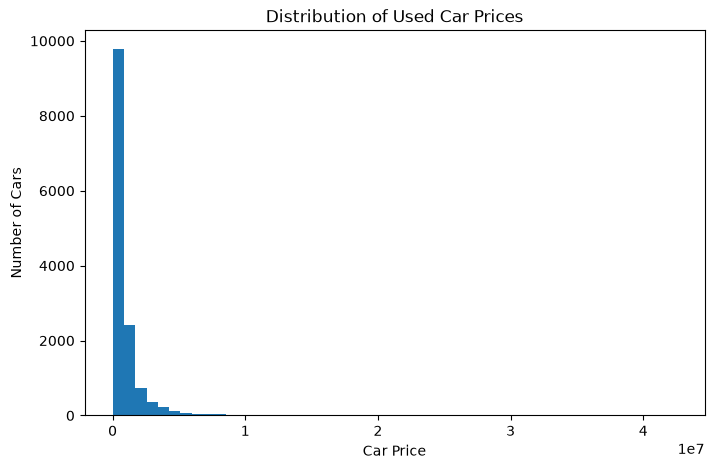

In [31]:
plt.figure(figsize=(8, 5))

plt.hist(df['AskPrice'], bins=50)

plt.xlabel('Car Price')
plt.ylabel('Number of Cars')
plt.title('Distribution of Used Car Prices')

plt.show()

In [32]:
df[df['Year'] < 1980]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
11260,Maruti Suzuki,Wagon-R,1931,93,88000.0,Manual,first,hybrid,349000.0
11392,Renault,Triber,1900,124,40000.0,Automatic,second,hybrid,440000.0
11458,Mahindra,Jeep,1978,46,100000.0,Manual,second,Diesel,200000.0
12545,Maruti Suzuki,Swift,1920,104,60000.0,Manual,first,Petrol,519000.0


In [33]:
df = df[df['Year'] >= 1978]

In [34]:
df.shape

(13906, 9)

In [35]:
df['Year'].min()

np.int64(1978)

In [36]:
df['Age'].describe()

count    13906.000000
mean         7.633755
std          4.127156
min          0.000000
25%          5.000000
50%          7.000000
75%         10.000000
max         46.000000
Name: Age, dtype: float64

In [37]:
df[df['Age'] > 30]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
1768,Mahindra,Jeep,1990,34,9000.0,Manual,second,Diesel,250000.0
7404,Maruti Suzuki,800,1986,38,68000.0,Manual,second,Petrol,120000.0
11458,Mahindra,Jeep,1978,46,100000.0,Manual,second,Diesel,200000.0


In [38]:
(df['Year'] + df['Age']).value_counts()

2024    13906
Name: count, dtype: int64

In [39]:
df.drop('Year', axis=1, inplace=True)

In [40]:
df.shape

(13906, 8)

In [41]:
df[['Brand', 'model', 'Transmission', 'Owner', 'FuelType']].nunique()

Brand            42
model           434
Transmission      2
Owner             2
FuelType          4
dtype: int64

In [42]:
df['Transmission'].unique()

<ArrowStringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

In [43]:
df['Owner'].unique()

<ArrowStringArray>
['second', 'first']
Length: 2, dtype: str

In [44]:
df['FuelType'].unique()

<ArrowStringArray>
['Petrol', 'Diesel', 'Hybrid/CNG', 'hybrid']
Length: 4, dtype: str

In [45]:
df['FuelType'].value_counts()

FuelType
Petrol        5370
Diesel        4829
hybrid        1900
Hybrid/CNG    1807
Name: count, dtype: int64

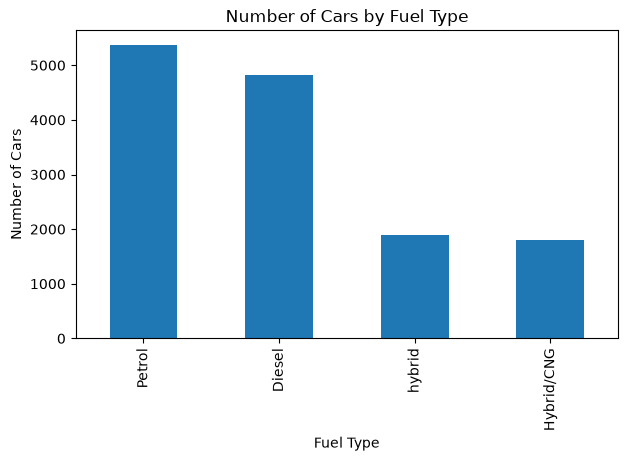

In [46]:
df['FuelType'].value_counts().plot(kind='bar', figsize=(7, 4))

plt.title('Number of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')

plt.show()

In [47]:
df['Brand'].value_counts().head(10)

Brand
Maruti Suzuki    4350
Hyundai          2308
Honda            1187
Toyota           1044
Mahindra          714
Tata              568
Mercedes-Benz     536
Volkswagen        445
BMW               378
Ford              373
Name: count, dtype: int64

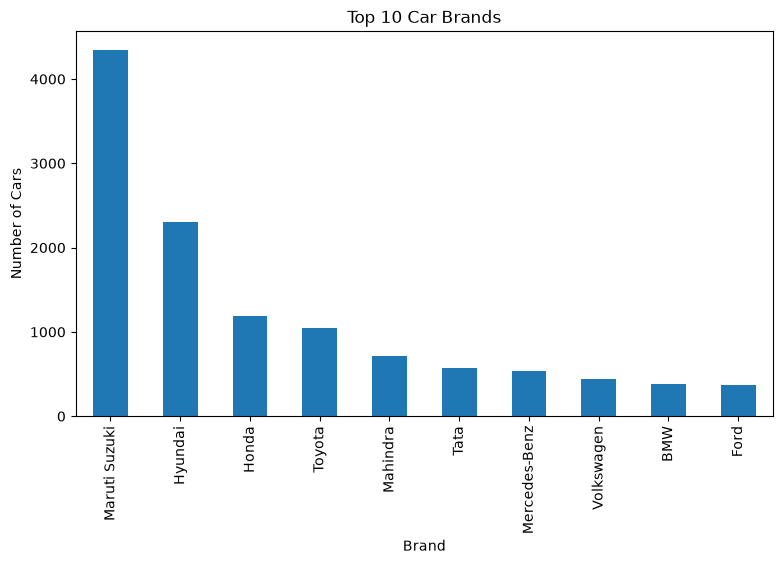

In [48]:
df['Brand'].value_counts().head(10).plot(kind='bar', figsize=(9, 5))

plt.title('Top 10 Car Brands')
plt.xlabel('Brand')
plt.ylabel('Number of Cars')

plt.show()

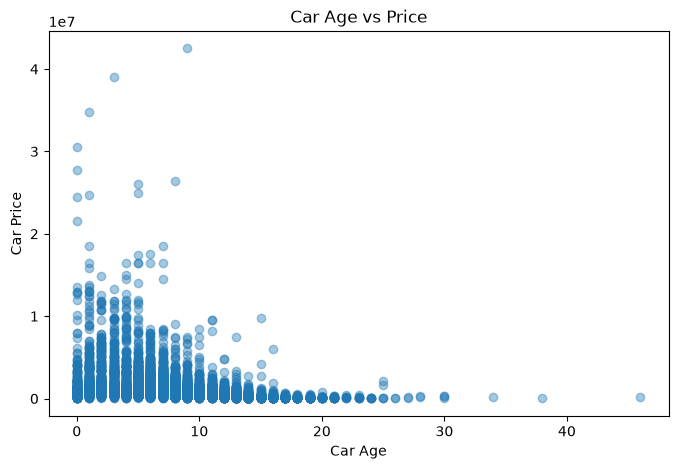

In [49]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Age'], df['AskPrice'], alpha=0.4)

plt.title('Car Age vs Price')
plt.xlabel('Car Age')
plt.ylabel('Car Price')

plt.show()

In [50]:
df[['Age', 'kmDriven', 'AskPrice']].corr()

,Age,kmDriven,AskPrice
Age,1.000000,0.281016,-0.298897
kmDriven,0.281016,1.000000,-0.132156
AskPrice,-0.298897,-0.132156,1.000000


In [51]:
df.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
0,Honda,City,23,98000.0,Manual,second,Petrol,195000.0
1,Toyota,Innova,15,190000.0,Manual,second,Diesel,375000.0
2,Volkswagen,VentoTest,14,77246.0,Manual,first,Diesel,184999.0
3,Maruti Suzuki,Swift,7,83500.0,Manual,second,Diesel,565000.0
4,Maruti Suzuki,Baleno,5,45000.0,Automatic,first,Petrol,685000.0


In [52]:
df.shape

(13906, 8)

In [53]:
df.isnull().sum()

Brand           0
model           0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

In [54]:
X = df.drop('AskPrice', axis=1)

y = df['AskPrice']

In [55]:
X.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType
0,Honda,City,23,98000.0,Manual,second,Petrol
1,Toyota,Innova,15,190000.0,Manual,second,Diesel
2,Volkswagen,VentoTest,14,77246.0,Manual,first,Diesel
3,Maruti Suzuki,Swift,7,83500.0,Manual,second,Diesel
4,Maruti Suzuki,Baleno,5,45000.0,Automatic,first,Petrol


In [56]:
y.head()

0    195000.0
1    375000.0
2    184999.0
3    565000.0
4    685000.0
Name: AskPrice, dtype: float64

In [57]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (13906, 7)
Target shape: (13906,)


In [58]:
categorical_columns = ['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

In [59]:
X = pd.get_dummies(X, columns=categorical_columns, drop_first=True, dtype=int)

In [60]:
X.head()

,Age,kmDriven,Brand_Ashok,Brand_Aston Martin,Brand_Audi,Brand_BMW,Brand_Bajaj,Brand_Bentley,Brand_Chevrolet,Brand_Citroen,...,model_i20 Active,model_i20 N Line,model_maruti-suzuki-brezza,model_maruti-suzuki-dzire,model_tata-punch,Transmission_Manual,Owner_second,FuelType_Hybrid/CNG,FuelType_Petrol,FuelType_hybrid
0,23,98000.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,1,0
1,15,190000.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
2,14,77246.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,7,83500.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
4,5,45000.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [61]:
X.shape

(13906, 481)

In [62]:
from sklearn.model_selection import train_test_split

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [64]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (11124, 481)
X_test: (2782, 481)
y_train: (11124,)
y_test: (2782,)


In [65]:
from sklearn.linear_model import LinearRegression

In [66]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


In [67]:
# Predict car prices using testing data
y_pred = model.predict(X_test)

# Display first 10 predicted prices
print("First 10 Predicted Prices:")
print(y_pred[:10])

First 10 Predicted Prices:
[2383049.27054132  527356.56234014 4158995.81856871  473693.32856354
  763925.73550094 3641891.38081929  912564.75993137  632397.71367336
  603402.95562603   37315.92903023]


In [68]:
# Create a comparison table
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

# Display first 10 results
comparison.head(10)

,Actual Price,Predicted Price
0,1050000.0,2.383049e+06
1,590000.0,5.273566e+05
2,6300000.0,4.158996e+06
3,299000.0,4.736933e+05
4,515000.0,7.639257e+05
5,4199000.0,3.641891e+06
6,642000.0,9.125648e+05
7,850000.0,6.323977e+05
8,450000.0,6.034030e+05
9,150000.0,3.731593e+04


In [69]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Performance")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Model Performance
MAE: 466143.72132649575
MSE: 814145096584.9048
RMSE: 902299.8928210647
R2 Score: 0.5608539093425888


In [70]:
from sklearn.tree import DecisionTreeRegressor

# Create the model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_pred = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Model Performance")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Model Performance
MAE: 232954.29363767072
MSE: 1023315320050.753
RMSE: 1011590.4902927632
R2 Score: 0.4480284605346626


In [72]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [73]:
# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Model Performance")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Model Performance
MAE: 178842.05593676653
MSE: 283379159111.7782
RMSE: 532333.691505411
R2 Score: 0.8471465953431019


In [74]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'MAE': [mae, dt_mae, rf_mae],
    'RMSE': [rmse, dt_rmse, rf_rmse],
    'R2 Score': [r2, dt_r2, rf_r2]
})

pd.options.display.float_format = '{:,.2f}'.format

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,"466,143.72","902,299.89",0.56
1,Decision Tree,"232,954.29","1,011,590.49",0.45
2,Random Forest,"178,842.06","532,333.69",0.85


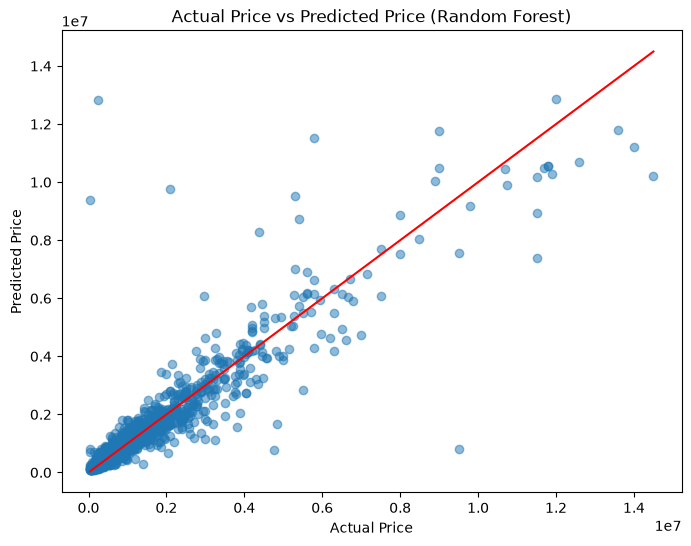

In [75]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_pred, alpha=0.5)

# Draw a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Price vs Predicted Price (Random Forest)")

plt.show()

In [76]:
# Get feature importance from Random Forest
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 important features
importance.head(15)

,Feature,Importance
0,Age,0.15
196,model_G Class,0.09
28,Brand_Mercedes-Benz,0.07
22,Brand_Land Rover,0.05
1,kmDriven,0.05
5,Brand_BMW,0.05
476,Transmission_Manual,0.05
257,model_LX,0.03
33,Brand_Porsche,0.03
259,model_Land Cruiser,0.03


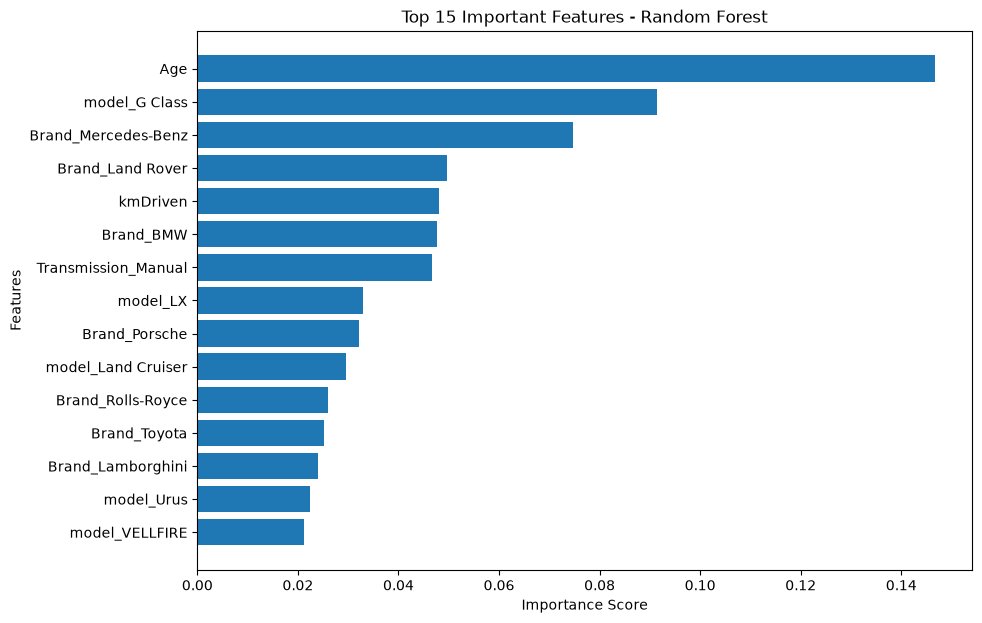

In [77]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance.head(15)['Feature'],
    importance.head(15)['Importance']
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Important Features - Random Forest")

plt.gca().invert_yaxis()

plt.show()

In [78]:
# Create details of a new car
new_car = pd.DataFrame({
    'Brand': ['Maruti Suzuki'],
    'model': ['Swift'],
    'Age': [5],
    'kmDriven': [45000],
    'Transmission': ['Manual'],
    'Owner': ['first'],
    'FuelType': ['Petrol']
})

new_car

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType
0,Maruti Suzuki,Swift,5,45000,Manual,first,Petrol


In [79]:
# Convert categorical columns into numerical columns
new_car_encoded = pd.get_dummies(
    new_car,
    columns=['Brand', 'model', 'Transmission', 'Owner', 'FuelType'],
    drop_first=True,
    dtype=int
)

# Match the columns with training data
new_car_encoded = new_car_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("New car data prepared successfully!")
print("Shape:", new_car_encoded.shape)

New car data prepared successfully!
Shape: (1, 481)


In [80]:
# Predict the price using Random Forest
predicted_price = rf_model.predict(new_car_encoded)

# Display the predicted price
print("Predicted Car Price: ₹", round(predicted_price[0], 2))

Predicted Car Price: ₹ 862603.89


In [81]:
import joblib

# Save the trained model
joblib.dump(rf_model, 'used_car_price_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [82]:
# Save the training column names
joblib.dump(
    X_train.columns.tolist(),
    'used_car_columns.pkl'
)

print("Training columns saved successfully!")

Training columns saved successfully!


In [83]:
# Load the saved model
loaded_model = joblib.load('used_car_price_model.pkl')

# Load the saved column names
loaded_columns = joblib.load('used_car_columns.pkl')

print("Model loaded successfully!")
print("Number of columns:", len(loaded_columns))

Model loaded successfully!
Number of columns: 481


In [84]:
# Predict using the loaded model
loaded_prediction = loaded_model.predict(new_car_encoded)

print("Prediction using loaded model: ₹", round(loaded_prediction[0], 2))

Prediction using loaded model: ₹ 862603.89


In [85]:
# Store available categories from our dataset

categorical_columns = [
    'Brand',
    'model',
    'Transmission',
    'Owner',
    'FuelType'
]

car_categories = {}

for col in categorical_columns:
    car_categories[col] = sorted(df[col].unique().tolist())

# Save category information
joblib.dump(car_categories, 'used_car_categories.pkl')

print("Car categories saved successfully!")

Car categories saved successfully!


In [86]:

import joblib

# Create a mapping between brands and their models
brand_models = {}

for brand in df['Brand'].unique():
    models = sorted(
        df[df['Brand'] == brand]['model'].unique().tolist()
    )
    brand_models[brand] = models

# Load existing category information
car_categories = joblib.load('used_car_categories.pkl')

# Add brand-model mapping
car_categories['brand_models'] = brand_models

# Save the updated file
joblib.dump(car_categories, 'used_car_categories.pkl')

print("Brand and model mapping saved successfully!")


Brand and model mapping saved successfully!


In [87]:
swift_data = df[
    (df['Brand'] == 'Maruti Suzuki') &
    (df['model'] == 'Swift')
]

swift_data[['Age', 'kmDriven', 'AskPrice']].sort_values(
    by='kmDriven'
).head(20)

,Age,kmDriven,AskPrice
1152,8,1.00,"510,000.00"
1287,1,3.00,"760,000.00"
5168,9,10.00,"380,000.00"
4259,17,25.00,"70,000.00"
8550,12,112.00,"399,000.00"
6802,0,"2,000.00","900,000.00"
2005,0,"2,600.00","865,000.00"
9889,0,"3,455.00","950,000.00"
5757,1,"5,000.00","750,000.00"
6415,5,"5,500.00","600,000.00"


In [88]:
swift_data['kmDriven'].describe()

count       392.00
mean     68,599.42
std      43,937.00
min           1.00
25%      45,000.00
50%      65,500.00
75%      85,000.00
max     620,287.00
Name: kmDriven, dtype: float64

In [89]:
swift_data[
    (swift_data['kmDriven'] < 1000) |
    (swift_data['kmDriven'] > 200000)
][['Age', 'kmDriven', 'AskPrice']].sort_values(
    by='kmDriven'
)

,Age,kmDriven,AskPrice
1152,8,1.00,"510,000.00"
1287,1,3.00,"760,000.00"
5168,9,10.00,"380,000.00"
4259,17,25.00,"70,000.00"
8550,12,112.00,"399,000.00"
6458,14,"620,287.00","86,000.00"


In [90]:
print("Cars with less than 1000 km:")
print(len(df[df['kmDriven'] < 1000]))

print("\nCars with more than 200000 km:")
print(len(df[df['kmDriven'] > 200000]))

print("\nMaximum kilometres:")
print(df['kmDriven'].max())

Cars with less than 1000 km:
208

Cars with more than 200000 km:
179

Maximum kilometres:
980002.0


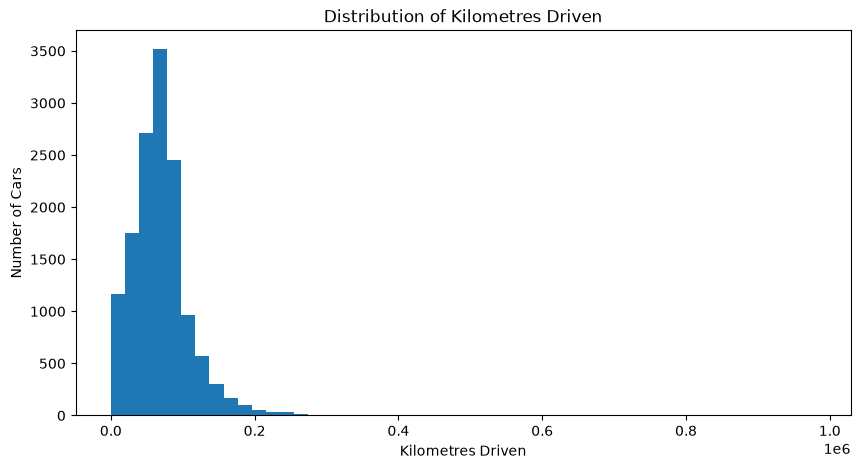

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['kmDriven'], bins=50)

plt.title('Distribution of Kilometres Driven')
plt.xlabel('Kilometres Driven')
plt.ylabel('Number of Cars')

plt.show()

In [92]:
Q1 = df['kmDriven'].quantile(0.25)
Q3 = df['kmDriven'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)


Q1: 44000.0
Q3: 87000.0
IQR: 43000.0
Lower Limit: -20500.0
Upper Limit: 151500.0


In [93]:
outliers = df[df['kmDriven'] > upper_limit]

print("Total cars:", len(df))

print("High mileage outliers:", len(outliers))

print("Outlier percentage:",
      round(len(outliers) / len(df) * 100, 2))

Total cars: 13906
High mileage outliers: 518
Outlier percentage: 3.73


In [94]:
low_km = df[
    (df['Age'] >= 3) &
    (df['kmDriven'] < 1000)
]

print("Older cars with very low mileage:", len(low_km))

Older cars with very low mileage: 154


In [95]:
df_clean = df[
    (df['kmDriven'] <= upper_limit) &
    ~((df['Age'] >= 3) & (df['kmDriven'] < 1000))
].copy()

print("Original dataset:", df.shape)
print("New cleaned dataset:", df_clean.shape)
print("Removed records:", len(df) - len(df_clean))

Original dataset: (13906, 8)
New cleaned dataset: (13234, 8)
Removed records: 672


In [96]:
X_clean = df_clean.drop('AskPrice', axis=1)
y_clean = df_clean['AskPrice']

categorical_columns = [
    'Brand', 'model', 'Transmission', 'Owner', 'FuelType'
]

X_clean = pd.get_dummies(
    X_clean,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Features shape:", X_clean.shape)
print("Target shape:", y_clean.shape)

Features shape: (13234, 475)
Target shape: (13234,)


In [97]:
valid_indices = X_train.index.intersection(df_clean.index)

X_train_clean = X_train.loc[valid_indices].copy()
y_train_clean = y_train.loc[valid_indices].copy()

print("Original training data:", X_train.shape)
print("New training data:", X_train_clean.shape)
print("Testing data:", X_test.shape)

print("Removed training records:",
      len(X_train) - len(X_train_clean))

Original training data: (11124, 481)
New training data: (10593, 481)
Testing data: (2782, 481)
Removed training records: 531


In [98]:
from sklearn.ensemble import RandomForestRegressor

rf_model_clean = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model_clean.fit(X_train_clean, y_train_clean)

print("New Random Forest model trained successfully!")

New Random Forest model trained successfully!


In [99]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

y_pred_clean = rf_model_clean.predict(X_test)

mae_clean = mean_absolute_error(y_test, y_pred_clean)
rmse_clean = np.sqrt(mean_squared_error(y_test, y_pred_clean))
r2_clean = r2_score(y_test, y_pred_clean)

print("MAE:", mae_clean)
print("RMSE:", rmse_clean)
print("R2 Score:", r2_clean)

MAE: 185474.12365582344
RMSE: 571104.1614893865
R2 Score: 0.8240708279150515


In [100]:
test_car = pd.DataFrame({
    'Brand': ['Maruti Suzuki'],
    'model': ['Swift'],
    'Age': [5],
    'kmDriven': [10000],
    'Transmission': ['Manual'],
    'Owner': ['First Owner'],
    'FuelType': ['Petrol']
})

for km in [10000, 25000, 50000, 75000, 100000]:

    test_car['kmDriven'] = km

    encoded_car = pd.get_dummies(
        test_car,
        columns=categorical_columns,
        dtype=int
    )

    encoded_car = encoded_car.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    old_price = rf_model.predict(encoded_car)[0]
    new_price = rf_model_clean.predict(encoded_car)[0]

    print("Kilometres:", km)
    print("Original Model:", round(old_price))
    print("Cleaned Model:", round(new_price))
    print()

Kilometres: 10000
Original Model: 569520
Cleaned Model: 562900

Kilometres: 25000
Original Model: 596820
Cleaned Model: 602520

Kilometres: 50000
Original Model: 539173
Cleaned Model: 540186

Kilometres: 75000
Original Model: 606200
Cleaned Model: 612100

Kilometres: 100000
Original Model: 599481
Cleaned Model: 599900



In [101]:
import sklearn

print(sklearn.__version__)

1.9.0


In [102]:
constraints = []

for col in X_train.columns:
    if col in ['Age', 'kmDriven']:
        constraints.append(-1)
    else:
        constraints.append(0)

print("Total constraints:", len(constraints))
print("Age constraint:", constraints[X_train.columns.get_loc('Age')])
print("Mileage constraint:", constraints[X_train.columns.get_loc('kmDriven')])

Total constraints: 481
Age constraint: -1
Mileage constraint: -1


In [103]:
rf_model_mono = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    monotonic_cst=constraints
)

rf_model_mono.fit(X_train, y_train)

print("Monotonic Random Forest trained successfully!")

Monotonic Random Forest trained successfully!


In [104]:
y_pred_mono = rf_model_mono.predict(X_test)

mae_mono = mean_absolute_error(y_test, y_pred_mono)
rmse_mono = np.sqrt(mean_squared_error(y_test, y_pred_mono))
r2_mono = r2_score(y_test, y_pred_mono)

print("MAE:", mae_mono)
print("RMSE:", rmse_mono)
print("R2 Score:", r2_mono)

MAE: 279113.6619150113
RMSE: 640715.4655197965
R2 Score: 0.7785694067820611


In [105]:
for km in [10, 1000, 10000, 25000, 50000, 75000, 100000]:

    test_car['kmDriven'] = km

    encoded_car = pd.get_dummies(
        test_car,
        columns=categorical_columns,
        dtype=int
    )

    encoded_car = encoded_car.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    old_price = rf_model.predict(encoded_car)[0]
    mono_price = rf_model_mono.predict(encoded_car)[0]

    print("Kilometres:", km)
    print("Original Model:", round(old_price))
    print("Monotonic Model:", round(mono_price))
    print()

Kilometres: 10
Original Model: 553080
Monotonic Model: 661140

Kilometres: 1000
Original Model: 553080
Monotonic Model: 661140

Kilometres: 10000
Original Model: 569520
Monotonic Model: 661140

Kilometres: 25000
Original Model: 596820
Monotonic Model: 658790

Kilometres: 50000
Original Model: 539173
Monotonic Model: 648946

Kilometres: 75000
Original Model: 606200
Monotonic Model: 648373

Kilometres: 100000
Original Model: 599481
Monotonic Model: 648373



In [106]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    random_state=42,
    monotonic_cst=constraints
)

hgb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [107]:
y_pred_hgb = hgb_model.predict(X_test)

mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))
r2_hgb = r2_score(y_test, y_pred_hgb)

print("MAE:", mae_hgb)
print("RMSE:", rmse_hgb)
print("R2 Score:", r2_hgb)

MAE: 286999.6627565098
RMSE: 703253.5301938391
R2 Score: 0.73323364718694


In [108]:
km_constraints = []

for col in X_train.columns:
    if col == 'kmDriven':
        km_constraints.append(-1)
    else:
        km_constraints.append(0)

rf_model_km = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    monotonic_cst=km_constraints
)

rf_model_km.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"monotonic_cst monotonic_cst: array-like of int of shape (n_features), default=NoneIndicates the monotonicity constraint to enforce on each feature. - 1: monotonically increasing - 0: no constraint - -1: monotonically decreasingIf monotonic_cst is None, no constraints are applied.Monotonicity constraints are not supported for: - multioutput regressions (i.e. when `n_outputs_ > 1`).Read more in the :ref:`User Guide <monotonic_cst_gbdt>`... versionadded:: 1.4","[0, -1, ...]"
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_feature

In [109]:
y_pred_km = rf_model_km.predict(X_test)

mae_km = mean_absolute_error(y_test, y_pred_km)
rmse_km = np.sqrt(mean_squared_error(y_test, y_pred_km))
r2_km = r2_score(y_test, y_pred_km)

print("MAE:", mae_km)
print("RMSE:", rmse_km)
print("R2 Score:", r2_km)

MAE: 187086.96498032392
RMSE: 546479.5882831012
R2 Score: 0.8389150006609828


In [110]:
for km in [10, 1000, 10000, 25000, 50000, 75000, 100000]:

    test_car['kmDriven'] = km

    encoded_car = pd.get_dummies(
        test_car,
        columns=categorical_columns,
        dtype=int
    )

    encoded_car = encoded_car.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    old_price = rf_model.predict(encoded_car)[0]
    new_price = rf_model_km.predict(encoded_car)[0]

    print("Kilometres:", km)
    print("Original Model:", round(old_price))
    print("New Model:", round(new_price))
    print()

Kilometres: 10
Original Model: 553080
New Model: 623385

Kilometres: 1000
Original Model: 553080
New Model: 623385

Kilometres: 10000
Original Model: 569520
New Model: 622335

Kilometres: 25000
Original Model: 596820
New Model: 617095

Kilometres: 50000
Original Model: 539173
New Model: 556874

Kilometres: 75000
Original Model: 606200
New Model: 548243

Kilometres: 100000
Original Model: 599481
New Model: 545197



In [111]:
test_car['kmDriven'] = 45000

for age in [1, 2, 3, 5, 7, 10, 15]:

    test_car['Age'] = age

    encoded_car = pd.get_dummies(
        test_car,
        columns=categorical_columns,
        dtype=int
    )

    encoded_car = encoded_car.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    old_price = rf_model.predict(encoded_car)[0]
    new_price = rf_model_km.predict(encoded_car)[0]

    print("Age:", age)
    print("Original Model:", round(old_price))
    print("New Model:", round(new_price))
    print()

Age: 1
Original Model: 698563
New Model: 703702

Age: 2
Original Model: 628441
New Model: 642399

Age: 3
Original Model: 614529
New Model: 640162

Age: 5
Original Model: 541570
New Model: 562082

Age: 7
Original Model: 527866
New Model: 564626

Age: 10
Original Model: 405720
New Model: 432094

Age: 15
Original Model: 164974
New Model: 200518



In [112]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    'max_depth': [15, 25, None],
    'min_samples_leaf': [1, 3, 5]
}

grid_search = GridSearchCV(
    RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    param_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

print("Best Validation MAE:", -grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1}
Best Validation MAE: 205377.947433788


In [113]:
print(type(rf_model))
print(type(rf_model_km))

<class 'sklearn.ensemble._forest.RandomForestRegressor'>
<class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [114]:
# Select five different cars from the dataset
test_cars = df.drop_duplicates(subset='Brand').sample(
    5, random_state=42
)

test_cars[['Brand', 'model', 'Age', 'kmDriven',
           'Transmission', 'Owner', 'FuelType']]

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType
502,Force,Motors FM Gurkha,1,"9,900.00",Manual,first,Diesel
47,Skoda,Kushaq,1,"12,000.00",Automatic,first,Petrol
15,Hyundai,Xcent,6,"130,000.00",Manual,second,Diesel
545,Mitsubishi,Pajero Sport,7,"68,000.00",Manual,second,Diesel
5,BMW,X3,10,"83,000.00",Automatic,first,Diesel


In [115]:
km_values = [10000, 25000, 50000, 75000, 100000, 150000]

results = []

for index, car in test_cars.iterrows():

    for km in km_values:

        new_car = car.drop('AskPrice').to_frame().T

        new_car['kmDriven'] = km

        new_car_encoded = pd.get_dummies(
            new_car,
            columns=categorical_columns,
            dtype=int
        )

        new_car_encoded = new_car_encoded.reindex(
            columns=X_train.columns,
            fill_value=0
        )

        original_price = rf_model.predict(new_car_encoded)[0]

        constrained_price = rf_model_km.predict(new_car_encoded)[0]

        results.append({
            'Brand': car['Brand'],
            'Model': car['model'],
            'Age': car['Age'],
            'kmDriven': km,
            'Original Model': round(original_price),
            'Constrained Model': round(constrained_price)
        })

comparison = pd.DataFrame(results)

comparison

,Brand,Model,Age,kmDriven,Original Model,Constrained Model
0,Force,Motors FM Gurkha,1,10000,1432040,1465377
1,Force,Motors FM Gurkha,1,25000,1408360,1414951
2,Force,Motors FM Gurkha,1,50000,1271900,1235692
3,Force,Motors FM Gurkha,1,75000,1230770,1211096
4,Force,Motors FM Gurkha,1,100000,1233970,1201714
5,Force,Motors FM Gurkha,1,150000,1235180,1199214
6,Skoda,Kushaq,1,10000,1519900,1659762
7,Skoda,Kushaq,1,25000,1506700,1501242
8,Skoda,Kushaq,1,50000,1501557,1413901
9,Skoda,Kushaq,1,75000,1439217,1357108


In [116]:
age_values = [1, 2, 3, 5, 7, 10, 15]

age_results = []

for index, car in test_cars.iterrows():

    for age in age_values:

        new_car = car.drop('AskPrice').to_frame().T

        new_car['Age'] = age
        new_car['kmDriven'] = 45000

        new_car_encoded = pd.get_dummies(
            new_car,
            columns=categorical_columns,
            dtype=int
        )

        new_car_encoded = new_car_encoded.reindex(
            columns=X_train.columns,
            fill_value=0
        )

        age_results.append({
            'Brand': car['Brand'],
            'Model': car['model'],
            'Age': age,
            'kmDriven': 45000,
            'Original Model': round(
                rf_model.predict(new_car_encoded)[0]
            ),
            'Constrained Model': round(
                rf_model_km.predict(new_car_encoded)[0]
            )
        })

age_comparison = pd.DataFrame(age_results)

age_comparison

,Brand,Model,Age,kmDriven,Original Model,Constrained Model
0,Force,Motors FM Gurkha,1,45000,1273870,1255193
1,Force,Motors FM Gurkha,2,45000,1192410,1208852
2,Force,Motors FM Gurkha,3,45000,1015860,1018581
3,Force,Motors FM Gurkha,5,45000,746835,787258
4,Force,Motors FM Gurkha,7,45000,702810,744159
5,Force,Motors FM Gurkha,10,45000,442162,473814
6,Force,Motors FM Gurkha,15,45000,168457,196837
7,Skoda,Kushaq,1,45000,1517437,1424878
8,Skoda,Kushaq,2,45000,1371070,1324113
9,Skoda,Kushaq,3,45000,1389020,1327268


In [117]:
import joblib

joblib.dump(rf_model, 'used_car_price_model_backup.pkl')

['used_car_price_model_backup.pkl']

In [118]:
joblib.dump(rf_model_km, 'used_car_price_model.pkl')

['used_car_price_model.pkl']

In [119]:
import os

print(os.path.abspath('used_car_price_model.pkl'))

C:\Users\ASHU\ProjectML\used_car_price_model.pkl
